## 📌 **Introduction**

Heart disease is one of the leading causes of death worldwide, and catching it early can save lives. In this notebook I build a **binary classifier** that predicts whether a person has heart disease (`1`) or not (`0`) from 13 clinical features such as age, sex, chest pain type, resting blood pressure, cholesterol and maximum heart rate.





| Step | What we'll cover |
|:-----|:-----|
| **Exploratory data analysis (EDA)** | The process of going through a dataset and discovering more about it. |
| **Model training**  | Create model(s) to learn to predict a target variable based on other variables. |
| **Model evaluation** | Evaluating a model's predictions using problem-specific evaluation metrics. |
| **Model comparison** | Comparing several different models to find the best one. |
| **Model hyperparameter tuning** | Once we've found a good model, can we tweak its hyperparameters to improve it? |
| **Feature importance** | Since we're predicting the presence of heart disease, are there some features/characteristics that are more important for prediction? |
| **Cross-validation** | If we do build a good model, can we be sure it will work on unseen data? |
| **Reporting what we've found** | If we had to present our work, what would we show someone? |

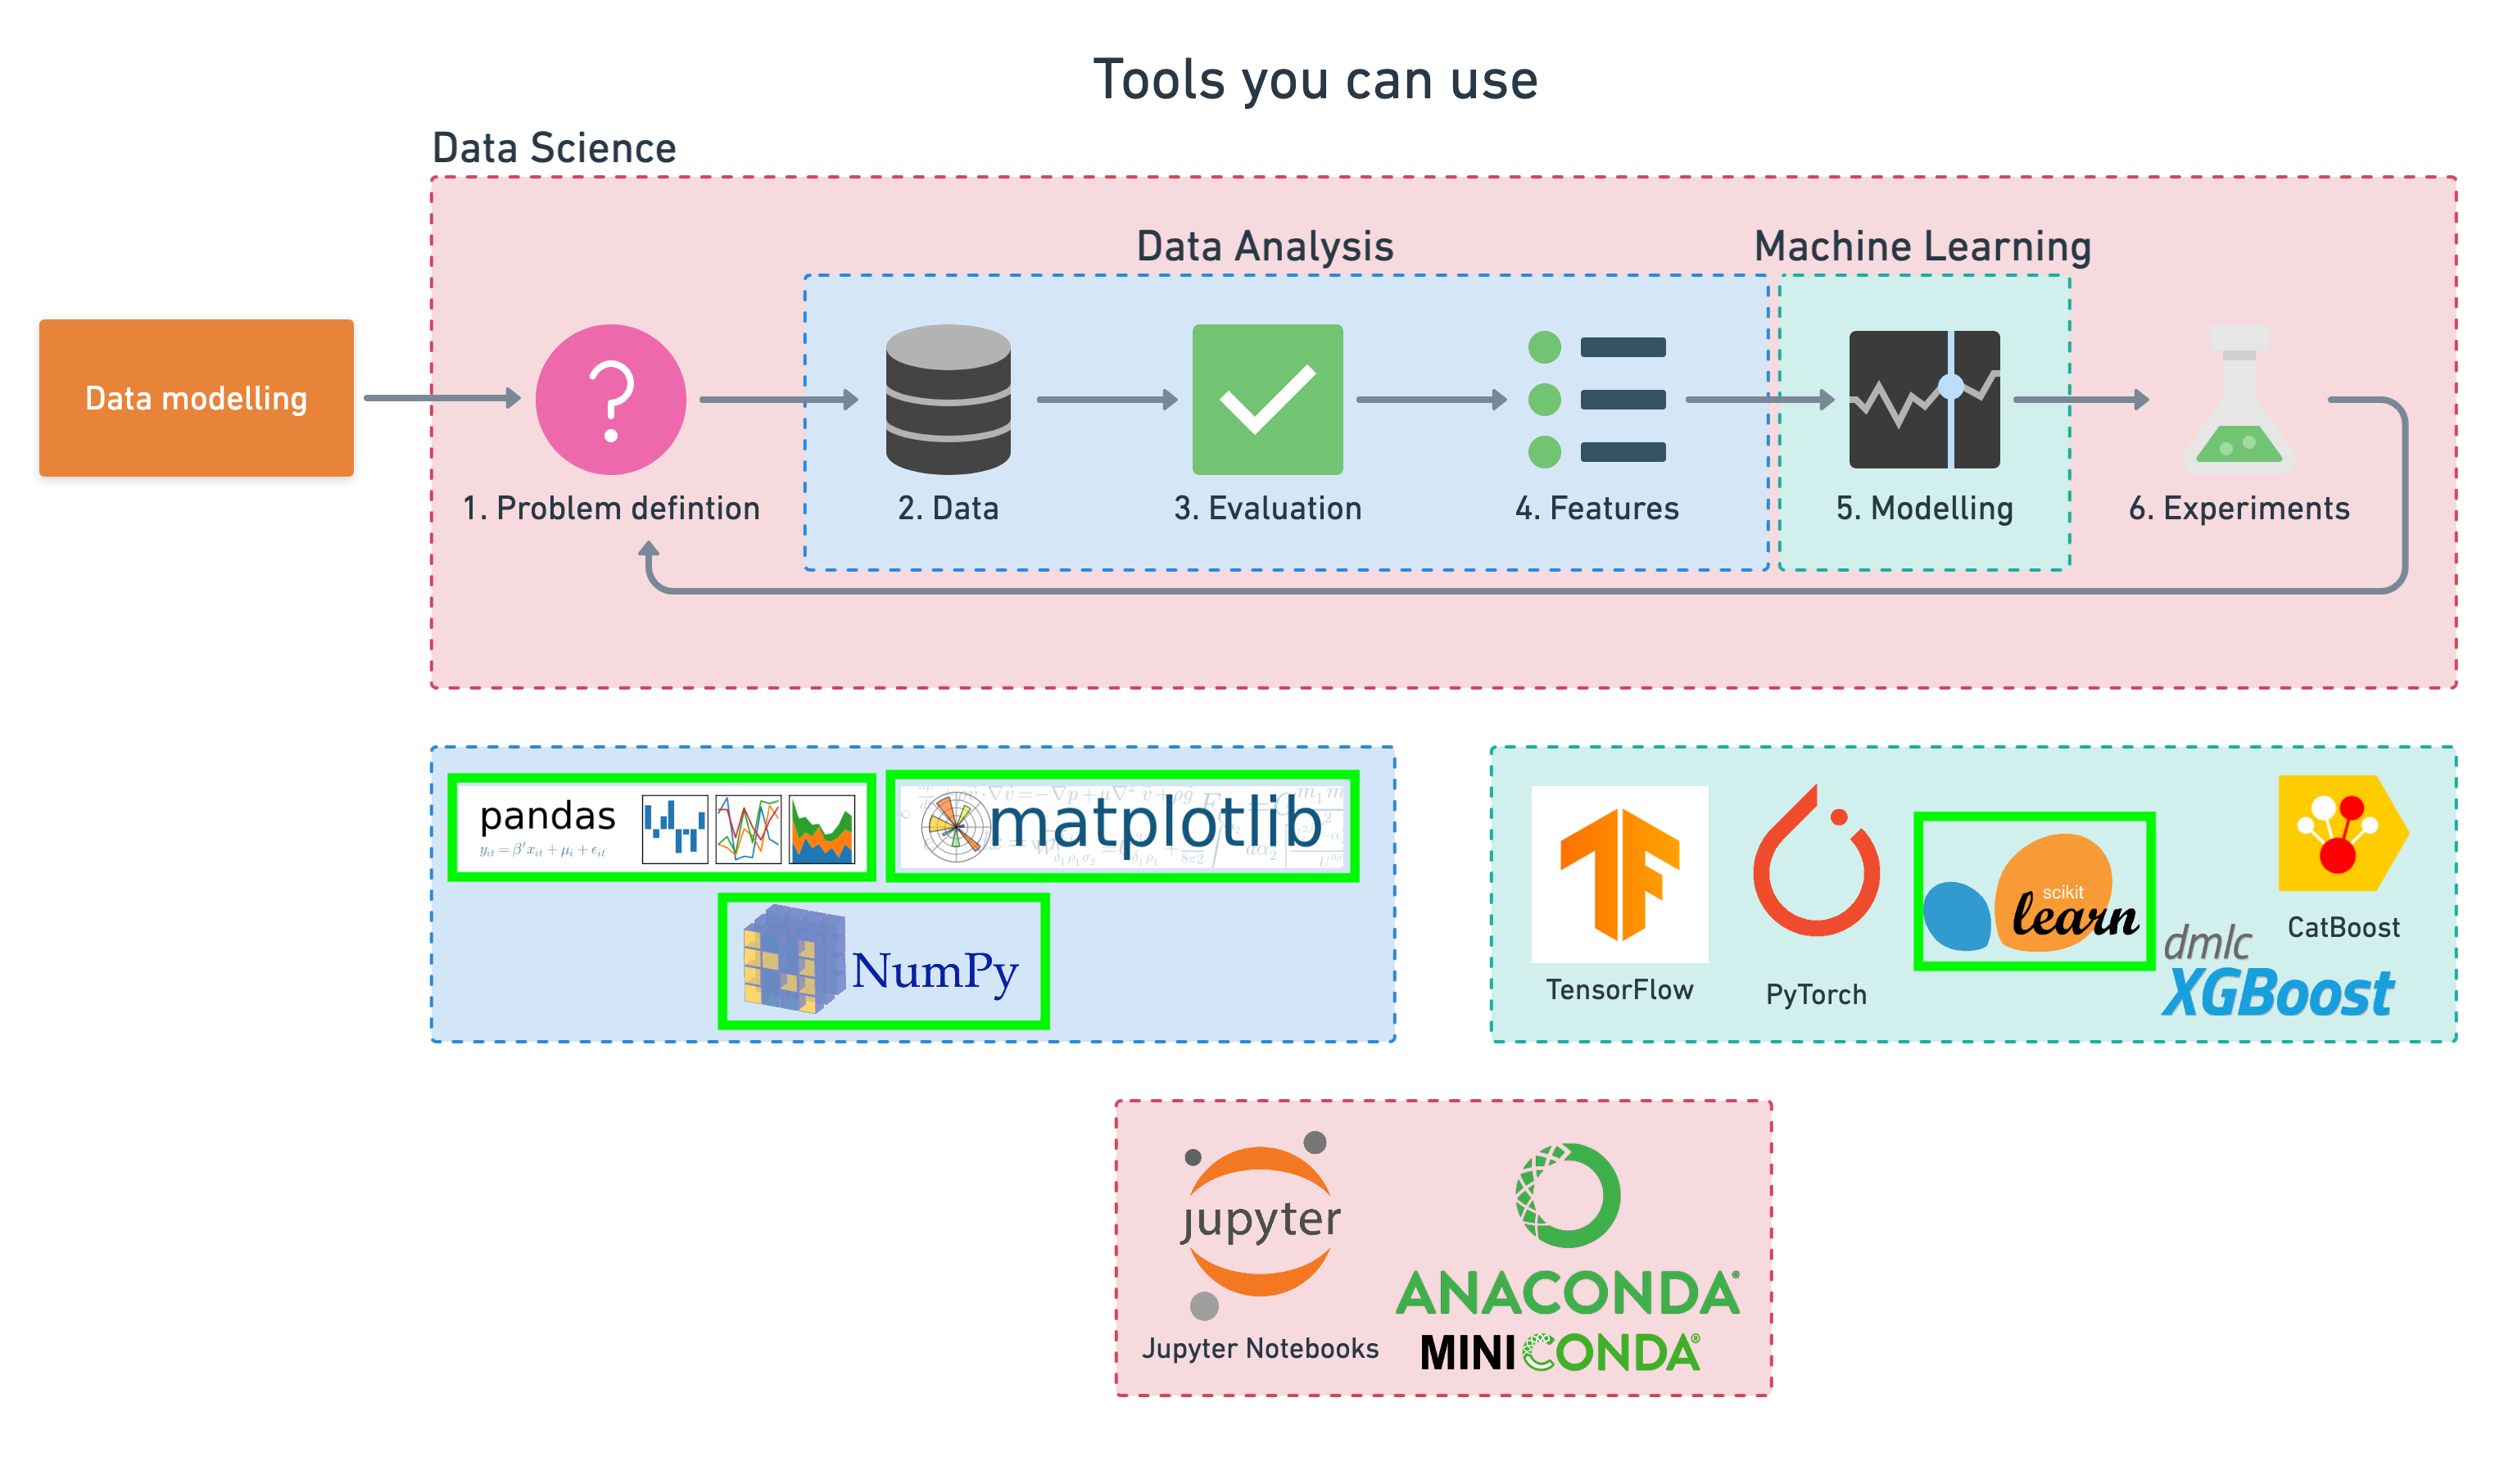

# **Targets**
  1. Create a **machine learning classification model** to predict whether a patient has heart disease.
2. Aim to achieve an accuracy of over **85%**.
   

In [54]:
# Importing libs to import, manuplate and visualize the data
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Print last updated
import datetime
print(f"Notebook last updated: {datetime.datetime.now()}\n")

# Print versions of libraries we're using (as long as yours are equal or greater than these, your code should work)
print(f"NumPy version: {np.__version__}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")

Notebook last updated: 2026-10-14 08:07:12.626176

NumPy version: 2.1.3
pandas version: 2.2.3
matplotlib version: 3.10.0


The following are the features we'll use to predict our target variable (heart disease or no heart disease).

| Feature  | Description | Example Values |
|:-----|:-----|:------|
| **age** | Age in years | 29, 45, 60 |
| **sex** | 1 = male; 0 = female | 0, 1  |
| **cp**  | Chest pain type | 0: Typical angina (chest pain), 1: Atypical angina (chest pain not related to heart), 2: Non-anginal pain (typically esophageal spasms (non heart related), 3: Asymptomatic (chest pain not showing signs of disease) |
| **trestbps** | Resting blood pressure (in mm Hg on admission to the hospital)  | 120, 140, 150 |
| **chol** | Serum cholesterol in mg/dl | 180, 220, 250 |
| **fbs** | Fasting blood sugar > 120 mg/dl (1 = true; 0 = false) | 0, 1 |
| **restecg** | Resting electrocardiographic results | 0: Nothing to note, 1: ST-T Wave abnormality, 2: Left ventricular hypertrophy  |
| **thalach** | Maximum heart rate achieved | 160, 180, 190 |
| **exang**  | Exercise induced angina (1 = yes; 0 = no) | 0, 1 |
| **oldpeak**  | ST depression (heart potentially not getting enough oxygen) induced by exercise relative to rest | 0.5, 1.0, 2.0  |
| **slope** | The slope of the peak exercise ST segment | 0: Upsloping, 1: Flatsloping, 2: Downsloping |
| **ca** | Number of major vessels (0-3) colored by fluoroscopy | 0, 1, 2, 3 |
| **thal** | Thalium stress result  | 1: Normal, 3: Normal, 6: Fixed defect, 7: Reversible defect |
| **target** | Have disease or not (1 = yes; 0 = no) | 0, 1 |


# **Loading the Data and Performing Exploratory Data Analysis (EDA)**

* Categorical Features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
* Numerical Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


In [55]:
df = pd.read_csv(r"/content/drive/MyDrive/Colab Notebooks/My_Projects/Heart_Disease_Classifier/Data/heart-disease.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [56]:
# Null values check
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [57]:
# Duplicate rows check
print(df.duplicated().sum())

1


In [58]:
# Drop duplicate rows
df.drop_duplicates(inplace = True)

In [59]:
# check for odd values in categorical features
df.ca.value_counts()

# ca should belong to 1,2,3 only
# we need to remove samples having ca = 4


,count
ca,
0,175
1,65
2,38
3,20
4,4


In [60]:
# Dropping samples where ca = 4
df = df[df['ca'] != 4]

In [61]:
df.thal.value_counts()
# There are two samples where thal is 0


,count
thal,
2,163
3,115
1,18
0,2


In [62]:
# Dropping samples where thal = 0
df = df[df['thal'] != 0]

In [63]:
df.shape
# 296 rows, 13 features, 1 target

(296, 14)

In [64]:
df.target.value_counts()

,count
target,
1,160
0,136


In [65]:
# normalized value counts
df.target.value_counts(normalize=True)*100
# 54 % are positive cases
# 46 % are negative cases

,proportion
target,
1,54.054054
0,45.945946



  * Since both are close to each other so, it can be considered as **Balanced**.
  * An **Unbalanced target** columns can be  harder for model


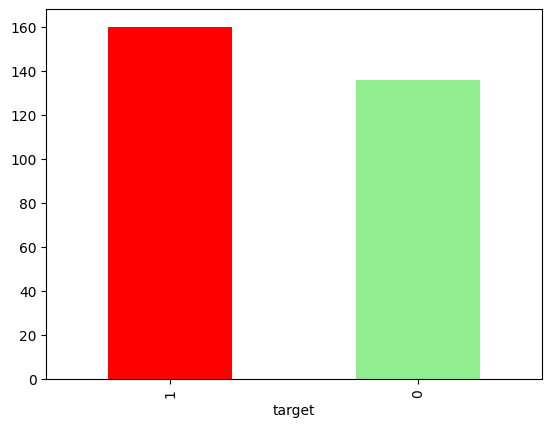

In [66]:
# plotting the value counts to compare
df.target.value_counts().plot(kind="bar", color=["red", "lightgreen"]);

  * Comparing one feature to another

In [67]:
# Comparing the target column with sex column
# 1 = male, 0 =  female
# 1 = +ve, 0 = -ve
pd.crosstab(index=df.target, columns=df.sex)

sex,0,1
target,,
0,24,112
1,71,89


(array([0, 1]), [Text(0, 0, '0'), Text(1, 0, '1')])

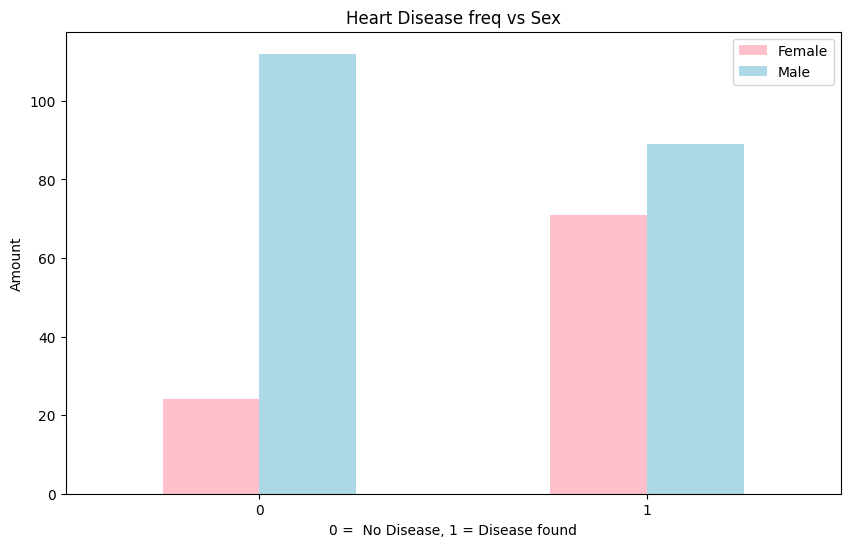

In [68]:
pd.crosstab(df.target, df.sex).plot(kind="bar",
                                    figsize=(10,6),
                                    color=["pink", "lightblue"]);
plt.title("Heart Disease freq vs Sex")
plt.xlabel("0 =  No Disease, 1 = Disease found")
plt.ylabel("Amount")
plt.legend(["Female", "Male"])
plt.xticks(rotation=0)

In [69]:
df.head(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


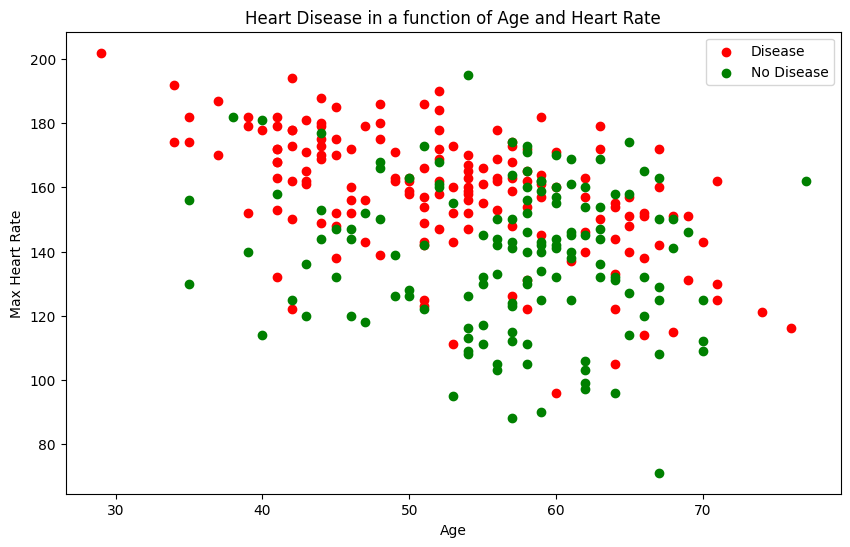

In [70]:
# comparing heartrate and age for positive and negative patients
plt.figure(figsize=(10,6))
# creating scatter plot for people having heart disease
plt.scatter(df.age[df.target == 1], df.thalach[df.target == 1], c = 'red')
plt.scatter(df.age[df.target == 0], df.thalach[df.target == 0], c = 'green')
plt.title("Heart Disease in a function of Age and Heart Rate")
plt.xlabel('Age')
plt.ylabel("Max Heart Rate")
plt.legend(["Disease", "No Disease"])
plt.show()

In [71]:
# Observations from above plot
# Younger ones have high Heart Rate
# Heart disease more found in range of 40-60 yrs and they have high heart rate

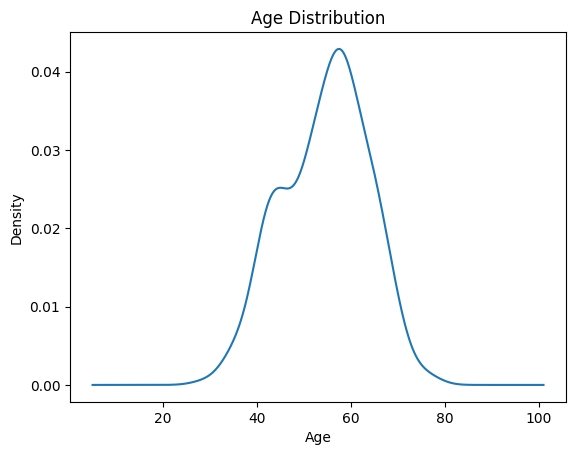

In [72]:
# Checking age distribution inside the data
df.age.plot(kind='kde')
plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()
# more data for age 30-70 years

* Box Plot:  to check outliers inside the data

download.svg

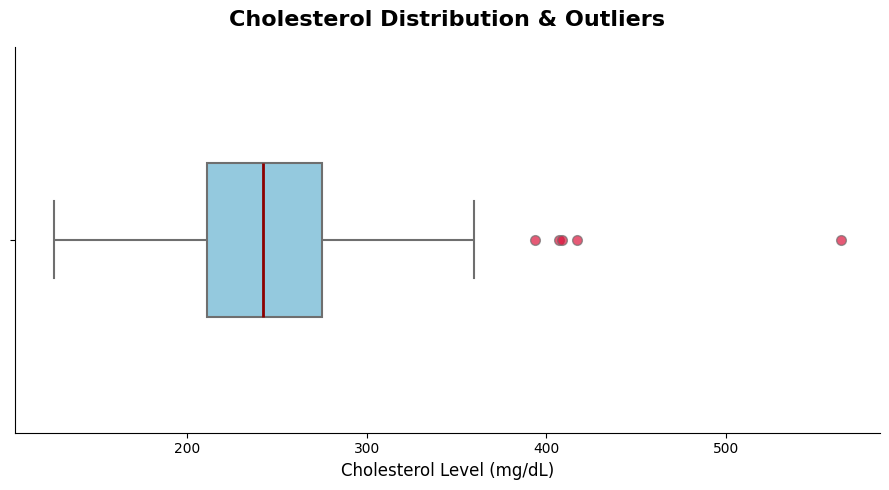

In [73]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x=df['chol'],
    color="skyblue",
    width=0.4,
    linewidth=1.5,
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'crimson',
        'markersize': 7,
        'alpha': 0.7
    },
    medianprops={'color': 'darkred', 'linewidth': 2}
)

plt.title("Cholesterol Distribution & Outliers",
          fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Cholesterol Level (mg/dL)", fontsize=12)
plt.ylabel("")

sns.despine()
plt.tight_layout()
plt.show()

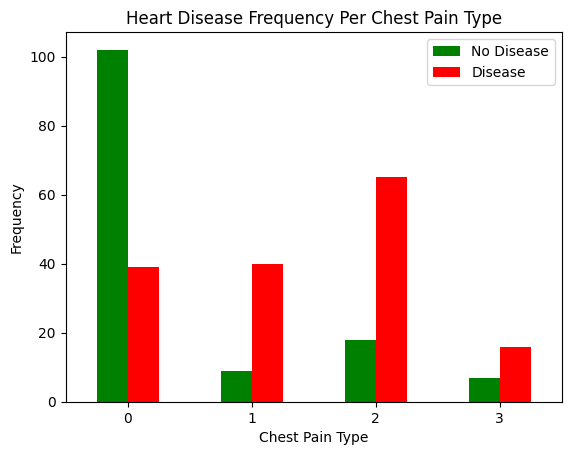

In [74]:
# comparing chest pain and heart disease frequency

pd.crosstab(index = df.cp, columns = df.target).plot(kind='bar',
                                                     color = ["green","red"])
plt.title("Heart Disease Frequency Per Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Frequency")
plt.legend(["No Disease", "Disease"])
plt.xticks(rotation = 0);

**Correlation matrix** :
A correlation matrix is a table that shows how strongly different numerical features are related to each other.

Absolute correlation	Interpretation:

| Correlation | Strength |
|:---|:---|
| +-(0.00–0.19) | Very weak |
| +-(0.20–0.39) | Weak |
| +-(0.40–0.59) | Moderate |
| +-(0.60–0.79) | Strong |
| +-(0.80–1.00) | Very strong |


In [75]:
corr_matrix = df.corr()
corr_matrix

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.089820,-0.061405,0.288701,0.200920,0.133022,-0.112365,-0.395989,0.098051,0.199373,-0.161758,0.364229,0.063373,-0.225453
sex,-0.089820,1.000000,-0.048023,-0.059520,-0.193749,0.036981,-0.072303,-0.058293,0.140791,0.102641,-0.028719,0.088788,0.212017,-0.285322
cp,-0.061405,-0.048023,1.000000,0.044610,-0.067926,0.118337,0.039106,0.296621,-0.383902,-0.142159,0.104675,-0.226203,-0.162660,0.423425
trestbps,0.288701,-0.059520,0.044610,1.000000,0.126705,0.183658,-0.117539,-0.051817,0.070501,0.196793,-0.126742,0.102042,0.063773,-0.148922
chol,0.200920,-0.193749,-0.067926,0.126705,1.000000,0.014286,-0.142039,-0.001947,0.062132,0.042144,0.005572,0.119006,0.082496,-0.076541
fbs,0.133022,0.036981,0.118337,0.183658,0.014286,1.000000,-0.082361,-0.007155,-0.001863,0.007062,-0.046550,0.151259,-0.017891,-0.004680
restecg,-0.112365,-0.072303,0.039106,-0.117539,-0.142039,-0.082361,1.000000,0.030001,-0.065623,-0.055528,0.090915,-0.111317,-0.008723,0.131716
thalach,-0.395989,-0.058293,0.296621,-0.051817,-0.001947,-0.007155,0.030001,1.000000,-0.383671,-0.346742,0.388453,-0.267861,-0.111961,0.426655
exang,0.098051,0.140791,-0.383902,0.070501,0.062132,-0.001863,-0.065623,-0.383671,1.000000,0.287812,-0.248879,0.146783,0.224178,-0.425085
oldpeak,0.199373,0.102641,-0.142159,0.196793,0.042144,0.007062,-0.055528,-0.346742,0.287812,1.000000,-0.577779,0.292905,0.211675,-0.428804


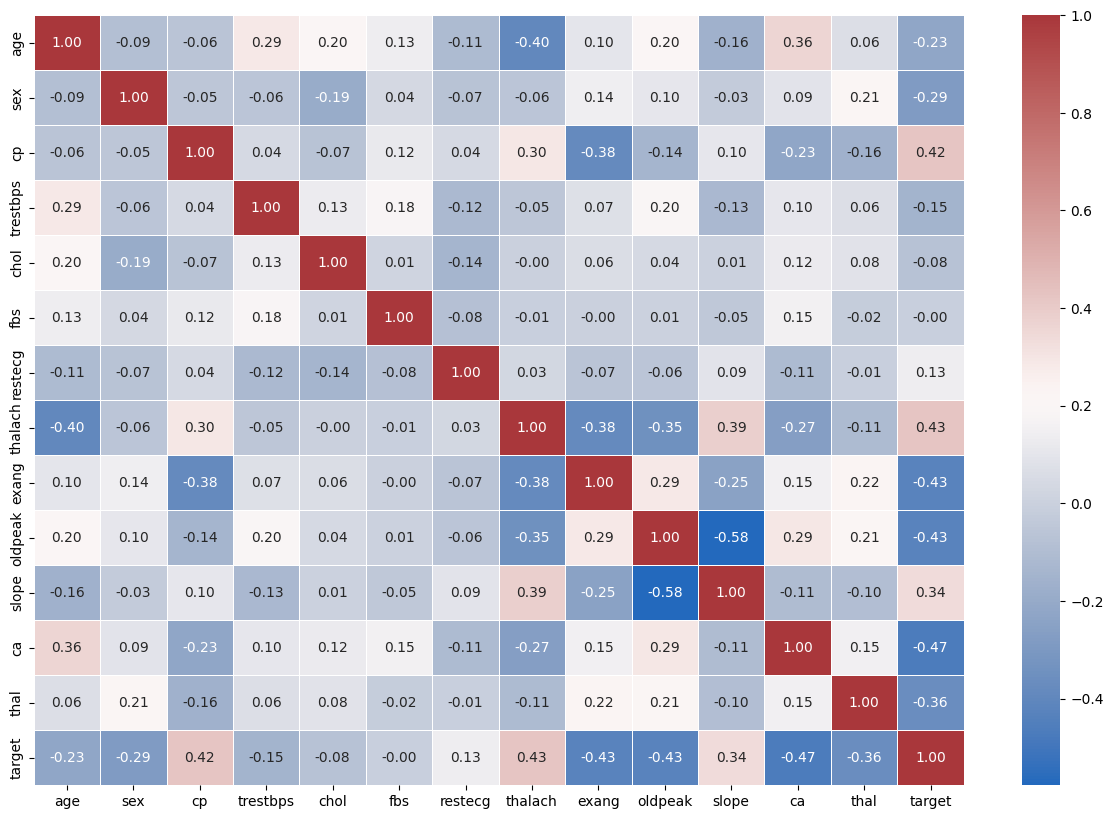

In [76]:
plt.figure(figsize=(15, 10))
sns.heatmap(corr_matrix,
            annot=True,
            linewidths=0.5,
            fmt= ".2f",
            cmap="vlag");

Important/Dominant features are:
  * cp, ca, exang, oldpeak, thalach

# **Data Preprocessing**

## Handling Categorical Features

In [77]:
dataset = pd.get_dummies(df, columns=['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal'], dtype= int)
dataset.head(5)

,age,trestbps,chol,thalach,oldpeak,target,sex_0,sex_1,cp_0,cp_1,...,slope_0,slope_1,slope_2,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_3
0,63,145,233,150,2.3,1,0,1,0,0,...,1,0,0,1,0,0,0,1,0,0
1,37,130,250,187,3.5,1,0,1,0,0,...,1,0,0,1,0,0,0,0,1,0
2,41,130,204,172,1.4,1,1,0,0,1,...,0,0,1,1,0,0,0,0,1,0
3,56,120,236,178,0.8,1,0,1,0,1,...,0,0,1,1,0,0,0,0,1,0
4,57,120,354,163,0.6,1,1,0,1,0,...,0,0,1,1,0,0,0,0,1,0


## Numeric Features Scaling

In [79]:
from sklearn.preprocessing import StandardScaler
standScaler = StandardScaler()
columns_to_scale = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
dataset[columns_to_scale] = standScaler.fit_transform(dataset[columns_to_scale])
dataset.head(5)

,age,trestbps,chol,thalach,oldpeak,target,sex_0,sex_1,cp_0,cp_1,...,slope_0,slope_1,slope_2,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_3
0,0.937219,0.756938,-0.272801,0.019152,1.065587,1,0,1,0,0,...,1,0,0,1,0,0,0,1,0,0
1,-1.937566,-0.090680,0.054821,1.632621,2.096070,1,0,1,0,0,...,1,0,0,1,0,0,0,0,1,0
2,-1.495292,-0.090680,-0.831685,0.978512,0.292725,1,1,0,0,1,...,0,0,1,1,0,0,0,0,1,0
3,0.163238,-0.655759,-0.214985,1.240155,-0.222517,1,0,1,0,1,...,0,0,1,1,0,0,0,0,1,0
4,0.273807,-0.655759,2.059094,0.586046,-0.394264,1,1,0,1,0,...,0,0,1,1,0,0,0,0,1,0


In [81]:
# Splitting the dataset
X = dataset.drop('target', axis = 1)
y = dataset.target

In [103]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state= 42)

# **Model Building**

In [104]:
# Using RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train,y_train)


RandomForestClassifier(random_state=42)

In [105]:
y_preds = model.predict(X_test)

In [106]:
from sklearn.metrics import accuracy_score

print(f"Accuracy of the base model is : {accuracy_score(y_test, y_preds)*100: .2f} %")

Accuracy of the base model is :  85.00 %


## Tuning Hyperparametrs

In [101]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [102]:
# We'll try to adjust following Hyperparameters :
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'max_features': ['sqrt', 'log2'],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}


In [113]:
from sklearn.model_selection import RandomizedSearchCV
clf = RandomForestClassifier()

model_2 = RandomizedSearchCV(
          estimator=clf,
          param_distributions=param_grid,
          n_iter=10,
          cv=5,
          verbose=2,
          random_state=42)

In [115]:
model_2.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END bootstrap=False, max_depth=30, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=200; total time=   0.3s
[CV] END bootstrap=False, max_depth=30, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=200; total time=   0.3s
[CV] END bootstrap=False, max_depth=30, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=200; total time=   0.5s
[CV] END bootstrap=False, max_depth=30, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=200; total time=   0.7s
[CV] END bootstrap=False, max_depth=30, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=200; total time=   1.1s
[CV] END bootstrap=True, max_depth=10, max_features=sqrt, min_samples_leaf=4, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END bootstrap=True, max_depth=10, max_features=sqrt, min_samples_leaf=4, min_samples_split=5, n_estimators=100; t

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(),
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [None, 10, 20, 30],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300]},
                   random_state=42, verbose=2)

In [119]:
y_preds_2 = model_2.predict(X_test)

In [120]:
print(f"Accuracy of the improved model is : {accuracy_score(y_test, y_preds_2)*100: .2f} %")

Accuracy of the improved model is :  86.67 %


* Improved model's accuracy score is greater than the base accuracy score

# **Evaluating the Model**

## Evaluating using Evaluation Functions

In [123]:
# Evaluating the Classifier model using evaluation functions
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Classifier metrics on the test set.\n")

print(f"Accuracy:{accuracy_score(y_test, y_preds_2)*100:.2f} %")
print(f"Precision_score:{precision_score(y_test, y_preds_2):.2f} ")
print(f"Recall_score:{recall_score(y_test, y_preds_2):.2f} ")
print(f"f1_score:{f1_score(y_test, y_preds_2):.2f}")

Classifier metrics on the test set.

Accuracy:86.67 %
Precision_score:0.90 
Recall_score:0.84 
f1_score:0.87


## ROC Curve

In [124]:
y_probs = model_2.predict_proba(X_test)
y_probs_positive = y_probs[:,1]
y_probs_positive

array([0.24124945, 0.97567315, 0.55272812, 0.46012134, 0.67026786,
       0.86902698, 0.40271026, 0.09460592, 0.10324218, 0.90458269,
       0.36443949, 0.38798843, 0.59037387, 0.07308824, 0.097934  ,
       0.95505766, 0.89198244, 0.47866076, 0.18644844, 0.98217495,
       0.67488458, 0.7620507 , 0.93491068, 0.29685877, 0.99388028,
       0.54159041, 0.07167157, 0.16380138, 0.1735732 , 0.03504146,
       0.07841812, 0.57338302, 0.1466734 , 0.12740701, 0.16759398,
       0.97256666, 0.03593347, 0.77627387, 0.12362047, 0.10649878,
       0.24679456, 0.18314298, 0.90040874, 0.45118768, 0.83941121,
       0.10252208, 0.77721081, 0.98665231, 0.89179762, 0.0397549 ,
       0.20882358, 0.97100531, 0.76971945, 0.83992664, 0.04188836,
       0.53966432, 0.81765971, 0.70037115, 0.68774952, 0.71981219])

In [125]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, y_probs_positive)

In [126]:
# Plotting ROC curve
def plot_roc_curve(fpr, tpr):
  """
  Plot a ROC curve given the false positive rate (fpr) and ture positive rate (tpr)
  of a model.
  """
  # Plot roc curve
  plt.plot(fpr, tpr, color = "orange", label = 'ROC')
  # Plot the line with no predective power (baseline)
  plt.plot([0,1],[0,1], color = "darkblue", linestyle = "--", label = "Guessing")

  # Customization the plot
  plt.xlabel("false positive rate (fpr)")
  plt.ylabel("True positive rate (tpr)")
  plt.title("Receiver Operating Characteristic (ROC) Curve")
  plt.legend()
  plt.show()

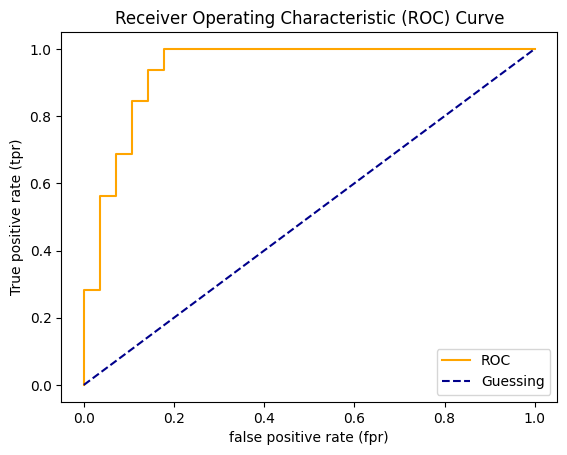

In [127]:
plot_roc_curve(fpr,tpr)

## Confusion Matrix

In [128]:
from sklearn.metrics import confusion_matrix
conf_matrix = confusion_matrix(y_test,y_preds_2)
conf_matrix

array([[25,  3],
       [ 5, 27]])

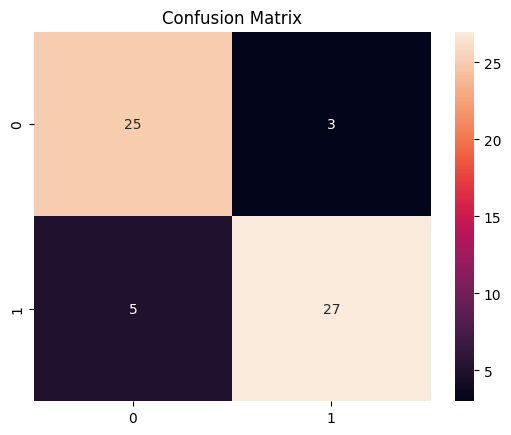

In [131]:
sns.heatmap(conf_matrix,annot=True)
plt.title("Confusion Matrix")
plt.show()

## Classification Report

In [132]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_preds_2))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86        28
           1       0.90      0.84      0.87        32

    accuracy                           0.87        60
   macro avg       0.87      0.87      0.87        60
weighted avg       0.87      0.87      0.87        60



# **Saving the Model**

In [133]:
# Saving 'model_2' to file:

import pickle
pickle.dump(model_2, open("Heart_disease_classifier.pkl", "wb"))

In [134]:
# load a saved model
loaded_model = pickle.load(open("Heart_disease_classifier.pkl", "rb"))

In [135]:
loaded_model.predict(X_test)

array([0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1])

In [136]:
np.array(y_test)

array([0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1])